In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    roc_auc_score,
)


In [4]:
# Load Exported Models & Prepare Evaluation Variables

artifacts = joblib.load("../models/heart_models.pkl")
log_model = artifacts["log_model"]
tree_model = artifacts["tree_model"]
scaler = artifacts["scaler"]
feature_columns = artifacts["feature_columns"]


cleaned_data = pd.read_csv("../data/cleaned_data.csv")
clean_data = cleaned_data.drop(columns="Unnamed: 0")
clean_data["sex"] = clean_data["sex"].map({"Male": 1, "Female": 0})
for col in ["fbs", "exang"]:
    clean_data[col] = clean_data[col].astype(int)

encoded_data = pd.get_dummies(
    clean_data, columns=["cp", "restecg", "slope"], drop_first=True, dtype=int
)

X = encoded_data.drop(columns=["target"])[feature_columns]
y = encoded_data["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 3. Generate predictions and probabilities for both models
y_pred_log = log_model.predict(X_test_scaled)
y_prob_log = log_model.predict_proba(X_test_scaled)[:, 1]

y_pred_tree = tree_model.predict(X_test)
y_prob_tree = tree_model.predict_proba(X_test)[:, 1]

In [5]:
# Exporting Results
results = pd.DataFrame({
    "Model": ["Logistic Regression", "Decision Tree"],
    "Train Accuracy": [log_model.score(X_train_scaled, y_train),
                       tree_model.score(X_train, y_train)],
    "Test Accuracy": [accuracy_score(y_test, y_pred_log),
                      accuracy_score(y_test, y_pred_tree)],
    "Precision": [precision_score(y_test, y_pred_log),
                  precision_score(y_test, y_pred_tree)],
    "Recall": [recall_score(y_test, y_pred_log),
               recall_score(y_test, y_pred_tree)],
    "ROC AUC": [roc_auc_score(y_test, y_prob_log),
                roc_auc_score(y_test, y_prob_tree)],
}).round(3)
results


,Model,Train Accuracy,Test Accuracy,Precision,Recall,ROC AUC
0,Logistic Regression,0.818,0.810,0.807,0.863,0.896
1,Decision Tree,0.795,0.783,0.816,0.784,0.866


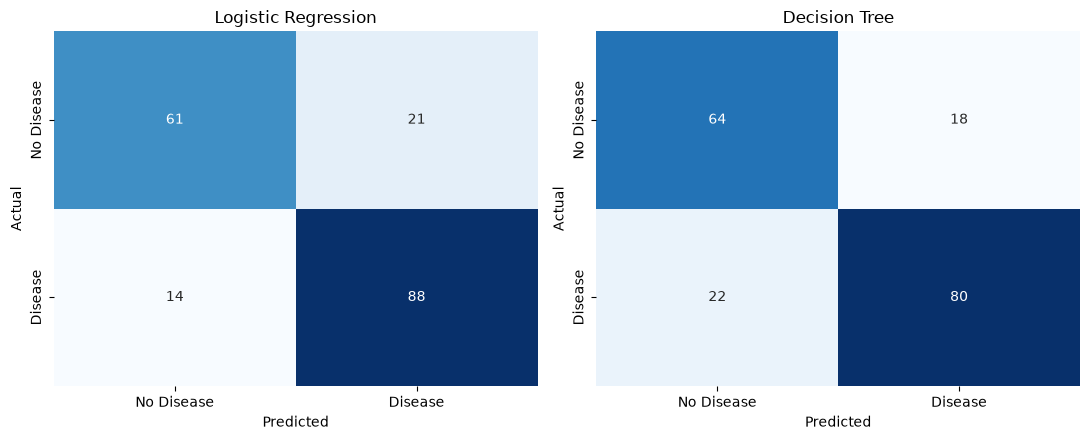

In [7]:
# Plot Comparision
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

for ax, (name, pred) in zip(axes, [("Logistic Regression", y_pred_log),
                                    ("Decision Tree", y_pred_tree)]):
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["No Disease", "Disease"],
                yticklabels=["No Disease", "Disease"])
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.savefig("../evaluations/confusion_matrices.png", dpi=500, bbox_inches="tight")
plt.show()

In [9]:
# Classification Report
print(classification_report(y_test, y_pred_log, target_names=["No Disease", "Disease"]))

              precision    recall  f1-score   support

  No Disease       0.81      0.74      0.78        82
     Disease       0.81      0.86      0.83       102

    accuracy                           0.81       184
   macro avg       0.81      0.80      0.81       184
weighted avg       0.81      0.81      0.81       184



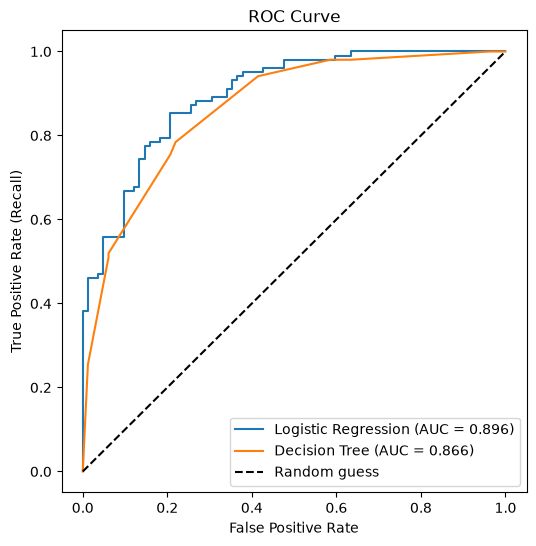

In [9]:
# ROC Curve
fpr_log, tpr_log, _ = roc_curve(y_test, y_prob_log)
fpr_tree, tpr_tree, _ = roc_curve(y_test, y_prob_tree)

plt.figure(figsize=(6, 6))
plt.plot(fpr_log, tpr_log, label=f"Logistic Regression (AUC = {roc_auc_score(y_test, y_prob_log):.3f})")
plt.plot(fpr_tree, tpr_tree, label=f"Decision Tree (AUC = {roc_auc_score(y_test, y_prob_tree):.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random guess")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC Curve")
plt.legend()
plt.savefig("../evaluations/roc_curve.png", dpi=500, bbox_inches="tight")
plt.show()

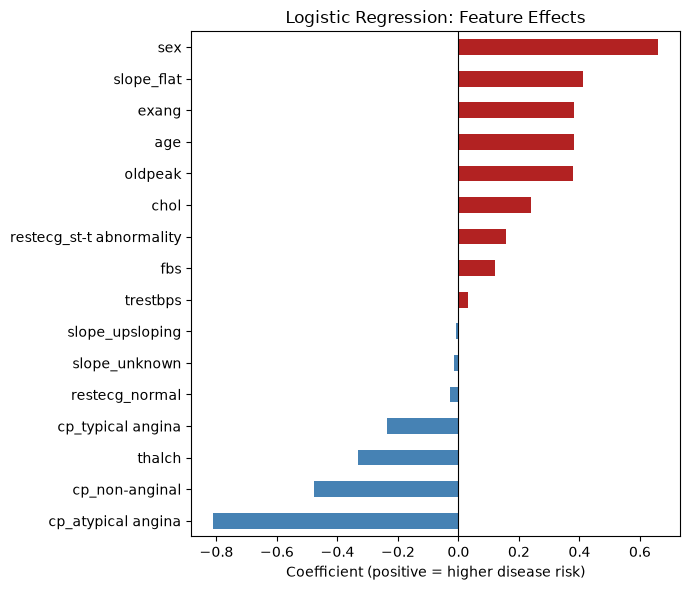

<Figure size 640x480 with 0 Axes>

In [15]:
# Logistic Regression: Feature Effects
coef = pd.Series(log_model.coef_[0], index=X.columns).sort_values()

plt.figure(figsize=(7, 6))
coef.plot(kind="barh", color=np.where(coef > 0, "firebrick", "steelblue"))
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Coefficient (positive = higher disease risk)")
plt.title("Logistic Regression: Feature Effects")
plt.tight_layout()
plt.savefig("../evaluation/log_reg_coefficients.png", dpi=500, bbox_inches="tight")
plt.show()

In [12]:
# Checking Importance of Every Parameters
importances = pd.Series(tree_model.feature_importances_, index=X.columns)
importances.sort_values(ascending=False).head(6).round(3)

exang                 0.438
cp_atypical angina    0.195
sex                   0.105
age                   0.103
thalch                0.052
oldpeak               0.036
dtype: float64